In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

## Forward kinetic modeling (retrieve Ct)

In [2]:
from __future__ import annotations

from abc import ABC, abstractmethod
from typing import ClassVar

import torch


def trapezoidal_integral(y: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
    """
    Compute cumulative trapezoidal integral of ``y`` over time ``t``.

    Args:
        y: Tensor with shape ``(T, N)`` where ``T`` is the number of time points
            and ``N`` is the number of voxel curves.
        t: Time points with shape ``(T,)``.

    Returns:
        Tensor with shape ``(T, N)`` where entry ``[i]`` is the integral from
        ``t[0]`` to ``t[i]``.
    """
    integral = torch.zeros_like(y)
    integral[1:, ...] = torch.cumulative_trapezoid(y, t, dim=0)
    return integral


def exponential_convolution_trapezoidal(
    Cp: torch.Tensor,
    t: torch.Tensor,
    rate: torch.Tensor,
) -> torch.Tensor:
    """
    Compute trapezoidal approximation of:
        conv(t_i) = ∫_0^{t_i} exp(-rate * (t_i - tau)) * Cp(tau) dtau

    using the stable recurrence:
        conv_i = E_i * conv_{i-1} + 0.5 * dt_i * (E_i * Cp_{i-1} + Cp_i),
        E_i = exp(-rate * dt_i)

    Args:
        Cp: ``(T, N)`` input function values.
        t: ``(T,)`` strictly increasing time points.
        rate: ``(N,)`` non-negative exponential rates.

    Returns:
        ``(T, N)`` convolution values.
    """
    T, N = Cp.shape
    rate_row = rate.unsqueeze(0)  # (1, N)
    dt = t[1:] - t[:-1]  # (T-1,)
    conv_steps = [Cp.new_zeros(N)]

    for i in range(1, T):
        dt_i = dt[i - 1].unsqueeze(-1)  # (1, 1) broadcastable
        E_i = torch.exp(-rate_row * dt_i)  # (1, N)
        prev = conv_steps[-1]
        conv_i = E_i.squeeze(0) * prev + 0.5 * dt_i.squeeze(-1) * (
            E_i.squeeze(0) * Cp[i - 1] + Cp[i]
        )
        conv_steps.append(conv_i)

    return torch.stack(conv_steps, dim=0)


class ForwardCompartmentModel(ABC):
    """
    Base class for forward dynamic PET compartment models.

    Input contract is intentionally minimal and explicit:
    - ``Cp``: ``(T,)`` arterial input curve
    - ``t``: ``(T,)`` time points (strictly increasing)
    - each parameter: scalar or flat vector ``(N,)`` where
      ``N = depth * height * width``

    Parameters are broadcast to a common ``(N,)`` shape. Each model returns:
    - ``(T,)`` for scalar parameters
    - ``(T, N)`` for vectorized parameters
    """

    parameter_names: ClassVar[tuple[str, ...]] = ()

    def __init__(
        self,
        dtype: torch.dtype | None = None,
        device: str | torch.device | None = None,
    ):
        self.dtype = dtype
        self.device = None if device is None else torch.device(device)

    def _to_tensor(self, value, *, like: torch.Tensor | None = None) -> torch.Tensor:
        if like is not None:
            return torch.as_tensor(value, dtype=like.dtype, device=like.device)
        if self.dtype is not None and self.device is not None:
            return torch.as_tensor(value, dtype=self.dtype, device=self.device)
        if self.dtype is not None:
            return torch.as_tensor(value, dtype=self.dtype)
        if self.device is not None:
            return torch.as_tensor(value, device=self.device)
        return torch.as_tensor(value)

    def __call__(self, Cp, t, **params) -> torch.Tensor:
        cp = self._to_tensor(Cp).reshape(-1)
        time = self._to_tensor(t, like=cp).reshape(-1)

        if cp.shape != time.shape:
            raise ValueError(f"Cp and t must have same shape, got {cp.shape} and {time.shape}.")
        if cp.numel() < 2:
            raise ValueError("At least two time points are required.")
        cp_finite = torch.isfinite(cp)
        time_finite = torch.isfinite(time)
        if not time_finite.all():
            bad_idx = int((~time_finite).nonzero(as_tuple=False)[0, 0].item())
            bad_value = time[bad_idx].item()
            raise ValueError(
                f"t must be finite. First non-finite at index {bad_idx} with value {bad_value}."
            )
        if not cp_finite.all():
            bad_idx = int((~cp_finite).nonzero(as_tuple=False)[0, 0].item())
            bad_value = cp[bad_idx].item()
            finite_cp = cp[cp_finite]
            if finite_cp.numel() > 0:
                cp_min = finite_cp.min().item()
                cp_max = finite_cp.max().item()
            else:
                cp_min = float("nan")
                cp_max = float("nan")
            raise ValueError(
                "Cp must be finite. "
                f"First non-finite at index {bad_idx} with value {bad_value}. "
                f"Finite Cp range=[{cp_min}, {cp_max}]."
            )
        if torch.any(torch.diff(time) <= 0):
            raise ValueError("t must be strictly increasing.")

        raw_params = {}
        for name in self.parameter_names:
            if name not in params:
                raise KeyError(f"Missing required parameter: {name}")
            value = self._to_tensor(params[name], like=cp)
            if value.ndim == 0:
                value = value.reshape(1)
            elif value.ndim == 1:
                value = value.reshape(-1)
            else:
                raise ValueError(
                    f"Parameter '{name}' must be scalar or flat vector (N,), "
                    f"got shape {tuple(value.shape)}."
                )
            raw_params[name] = value

        broadcasted = torch.broadcast_tensors(*(raw_params[name] for name in self.parameter_names))
        p = {name: value for name, value in zip(self.parameter_names, broadcasted)}

        ct = self.forward_cpet(cp, time, **p)
        if ct.ndim != 2 or ct.shape[0] != cp.numel():
            raise RuntimeError(
                f"{self.__class__.__name__}.forward_cpet must return (T, N), got {tuple(ct.shape)}."
            )

        return ct[:, 0] if ct.shape[1] == 1 else ct

    @abstractmethod
    def forward_cpet(self, Cp: torch.Tensor, t: torch.Tensor, **params) -> torch.Tensor:
        """
        Compute measured PET curve(s).

        Args:
            Cp: ``(T,)`` input function.
            t: ``(T,)`` time points.
            params: Broadcasted parameters, each with shape ``(N,)``.

        Returns:
            ``(T, N)`` measured curve(s).
        """
        raise NotImplementedError("Not implemented")


class OneTissueModelVB(ForwardCompartmentModel):
    """
    1T2K with blood-volume mixing:
        h(s) = K1 * exp(-k2 * s)
        Ct_tissue(t) = (h * Cp)(t)
        Ct(t) = (1 - vB) * Ct_tissue(t) + vB * Cp(t)
    """

    parameter_names: ClassVar[tuple[str, ...]] = ("K1", "k2", "vB")

    def forward_cpet(self, Cp: torch.Tensor, t: torch.Tensor, **params) -> torch.Tensor:
        K1, k2, vB = (params[name] for name in self.parameter_names)  # (N,)

        cp_2d = Cp.unsqueeze(-1).expand(-1, K1.numel())  # (T, N)

        # Ct_tissue(t) = K1 * ∫ exp(-k2*(t-tau)) * Cp(tau) dtau
        exp_convolution_term = exponential_convolution_trapezoidal(cp_2d, t, k2)
        ct_tissue = K1.unsqueeze(0) * exp_convolution_term

        return (1.0 - vB).unsqueeze(0) * ct_tissue + vB.unsqueeze(0) * cp_2d


class Irreversible2TCMVB(ForwardCompartmentModel):
    """
    Irreversible 2TCM (2T3K) with blood-volume mixing:
        h(s) = K1/(k2+k3) * (k3 + k2 * exp(-(k2+k3)s))
        Ct_tissue(t) = (h * Cp)(t)
        Ct(t) = (1 - vB) * Ct_tissue(t) + vB * Cp(t)
    """

    parameter_names: ClassVar[tuple[str, ...]] = ("K1", "k2", "k3", "vB")

    def forward_cpet(self, Cp: torch.Tensor, t: torch.Tensor, **params) -> torch.Tensor:
        K1, k2, k3, vB = (params[name] for name in self.parameter_names)  # (N,)

        eps = torch.finfo(Cp.dtype).eps
        lam = torch.clamp(k2 + k3, min=eps)  # (N,)

        cp_2d = Cp.unsqueeze(-1).expand(-1, K1.numel())  # (T, N)

        # Ct_tissue = K1/lam * [k3 * ∫Cp + k2 * ∫exp(-lam*(t-tau))Cp(tau)dtau]
        integral_cp = trapezoidal_integral(cp_2d, t)
        exp_convolution_term = exponential_convolution_trapezoidal(cp_2d, t, lam)

        ct_tissue = (K1 / lam).unsqueeze(0) * (
            k3.unsqueeze(0) * integral_cp + k2.unsqueeze(0) * exp_convolution_term
        )
        return (1.0 - vB).unsqueeze(0) * ct_tissue + vB.unsqueeze(0) * cp_2d


class Reversible2TCMVB(ForwardCompartmentModel):
    """
    Reversible 2TCM (2T4K) with blood-volume mixing:
        a1, a2 = 0.5 * [(k2+k3+k4) +- sqrt((k2+k3+k4)^2 - 4*k2*k4)]
        h(s) = K1/(a1-a2) * [ (a1-k3-k4)exp(-a1 s) - (a2-k3-k4)exp(-a2 s) ]
        Ct_tissue(t) = (h * Cp)(t)
        Ct(t) = (1 - vB) * Ct_tissue(t) + vB * Cp(t)
    """

    parameter_names: ClassVar[tuple[str, ...]] = ("K1", "k2", "k3", "k4", "vB")

    def forward_cpet(self, Cp: torch.Tensor, t: torch.Tensor, **params) -> torch.Tensor:
        K1, k2, k3, k4, vB = (params[name] for name in self.parameter_names)  # (N,)

        eps = torch.finfo(Cp.dtype).eps
        s = torch.clamp(k2 + k3 + k4, min=eps)
        discriminant = torch.clamp(s * s - 4.0 * k2 * k4, min=0.0)
        root = torch.sqrt(discriminant)
        a1 = 0.5 * (s + root)  # (N,)
        a2 = 0.5 * (s - root)  # (N,)
        denom = torch.clamp(a1 - a2, min=eps)  # (N,)

        cp_2d = Cp.unsqueeze(-1).expand(-1, K1.numel())  # (T, N)

        conv_a1 = exponential_convolution_trapezoidal(cp_2d, t, a1)
        conv_a2 = exponential_convolution_trapezoidal(cp_2d, t, a2)

        ct_tissue = (K1 / denom).unsqueeze(0) * (
            (a1 - k3 - k4).unsqueeze(0) * conv_a1
            - (a2 - k3 - k4).unsqueeze(0) * conv_a2
        )
        return (1.0 - vB).unsqueeze(0) * ct_tissue + vB.unsqueeze(0) * cp_2d

In [3]:
rev2tcm = Reversible2TCMVB()
irev2tcm = Irreversible2TCMVB()

# Load data

In [45]:
fits = pd.read_csv("../output/validation/voi_reference/voi_reference_fits.csv")
curves = np.load("../output/validation/voi_reference/voi_reference_curves.npz", allow_pickle=True)

In [46]:
list(curves.keys())

['sample_id',
 'npz_path',
 'voi_path',
 'group',
 'npz_sample_id',
 'time_minutes',
 'aif',
 'brain',
 'myocardium']

In [47]:
curves["sample_id"]

array(['AA1', 'AA2', 'AA3', 'AA4', 'AB1', 'AB2', 'AB3', 'AB4', 'AC1',
       'AD3', 'AF3', 'AF4', 'AG1', 'AG3', 'AG4', 'AH1', 'AH2', 'AH3',
       'AH4', 'AI4', 'AN1', 'AN2', 'AN4', 'AO2', 'AO3', 'AO4', 'AP2',
       'AP4', 'AQ1', 'AQ2', 'AQ3', 'AQ4', 'AR2', 'AR3', 'AV1', 'AV2',
       'AV3', 'AV4', 'AX1', 'AX2', 'AX4', 'M2', 'M3', 'M4', 'N2', 'N3',
       'O1', 'O2', 'O3', 'O4', 'P2', 'P3', 'P4', 'Q1', 'T4', 'U1', 'U2',
       'U4', 'V1', 'V3', 'V4', 'W1', 'W2', 'X1', 'X2', 'X3', 'Y2', 'Y3',
       'Z2', 'Z3'], dtype=object)

In [48]:
fits.method.unique()

<StringArray>
['cpp', 'lls', 'pypet']
Length: 3, dtype: str

In [49]:
fits.head()

,sample_id,npz_sample_id,group,region,model,method,K1,k2,k3,k4,vB,Ki,error_value,error_kind,status,iterations,npz_path,voi_path
0,AA1,AA1,15s,Brain,irr,cpp,0.257025,0.379298,0.062783,0.0,0.072111,0.036502,0.076016,rmse_native_grid,1,11.0,/Users/csa047/uit/phd/projects/OT-CycleGAN-PET...,/Users/csa047/uit/phd/datasets/pet/VOI_SUV/VOI...
1,AA1,AA1,15s,Myocardium,irr,cpp,1.103788,0.140441,0.092205,0.0,0.421680,0.437464,0.522331,rmse_native_grid,1,10.0,/Users/csa047/uit/phd/projects/OT-CycleGAN-PET...,/Users/csa047/uit/phd/datasets/pet/VOI_SUV/VOI...
2,AA1,AA1,15s,Brain,irr,lls,0.191099,0.249483,0.062943,0.0,0.117104,0.038500,0.011451,mse_interp_grid,success,NaN,/Users/csa047/uit/phd/projects/OT-CycleGAN-PET...,/Users/csa047/uit/phd/datasets/pet/VOI_SUV/VOI...
3,AA1,AA1,15s,Myocardium,irr,lls,1.089960,0.111274,0.088226,0.0,0.473856,0.482020,0.101776,mse_interp_grid,success,NaN,/Users/csa047/uit/phd/projects/OT-CycleGAN-PET...,/Users/csa047/uit/phd/datasets/pet/VOI_SUV/VOI...
4,AA1,AA1,15s,Brain,irr,pypet,0.266973,0.413180,0.066529,0.0,0.064254,0.037026,1.918487,rss_interp_grid,success,NaN,/Users/csa047/uit/phd/projects/OT-CycleGAN-PET...,/Users/csa047/uit/phd/datasets/pet/VOI_SUV/VOI...


In [50]:
fits.model.unique()

<StringArray>
['irr', 'rev']
Length: 2, dtype: str

In [51]:
def get_time(sid):
    iloc = np.where(curves["sample_id"] == sid)[0][0]
    return curves["time_minutes"][iloc]

def get_aif(sid):
    iloc = np.where(curves["sample_id"] == sid)[0][0]
    return curves["aif"][iloc]

def get_roi(sid, region):
    iloc = np.where(curves["sample_id"] == sid)[0][0]
    return curves[region.lower()][iloc]

In [73]:
models = dict(irr=irev2tcm, rev=rev2tcm)

In [53]:
def compute_fit(row):
    sid = row.sample_id
    time = torch.from_numpy(get_time(sid))
    aif = torch.from_numpy(get_aif(sid))
    model = models[row.model]
    params = dict(K1=row.K1, k2=row.k2, k3=row.k3, k4=row.k4, vB=row.vB)
    fit = model(aif, time, **params).numpy()
    return fit

def compute_rmse(row):
    sid = row.sample_id
    real_curve = get_roi(sid, row.region)
    rmse = np.sqrt(np.mean(np.square(real_curve - row.fit)))
    return rmse

In [54]:
fits["fit"] = fits.apply(compute_fit, axis=1)
fits["real_curve"] = fits.apply(lambda x: get_roi(x.sample_id, x.region), axis=1)
fits["RMSE"] = fits.apply(compute_rmse, axis=1)

# Quantitative RMSE analysis

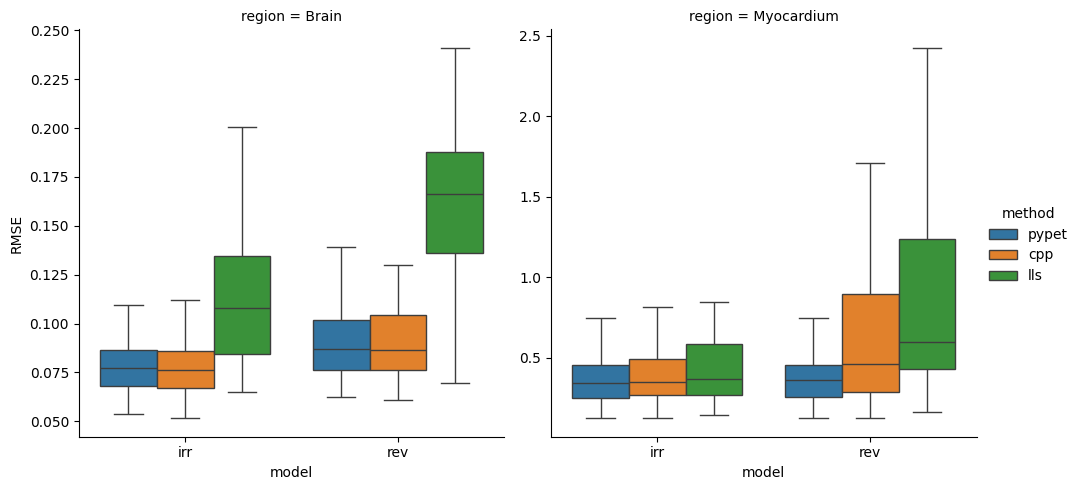

In [72]:
sns.catplot(
    fits,
    x="model",
    y="RMSE",
    hue="method",
    kind="box",
    col="region",
    sharey=False,
    showfliers=False,
    hue_order=["pypet", "cpp", "lls"]
)
plt.savefig("method-comparison.pdf", dpi=600)
plt.show()

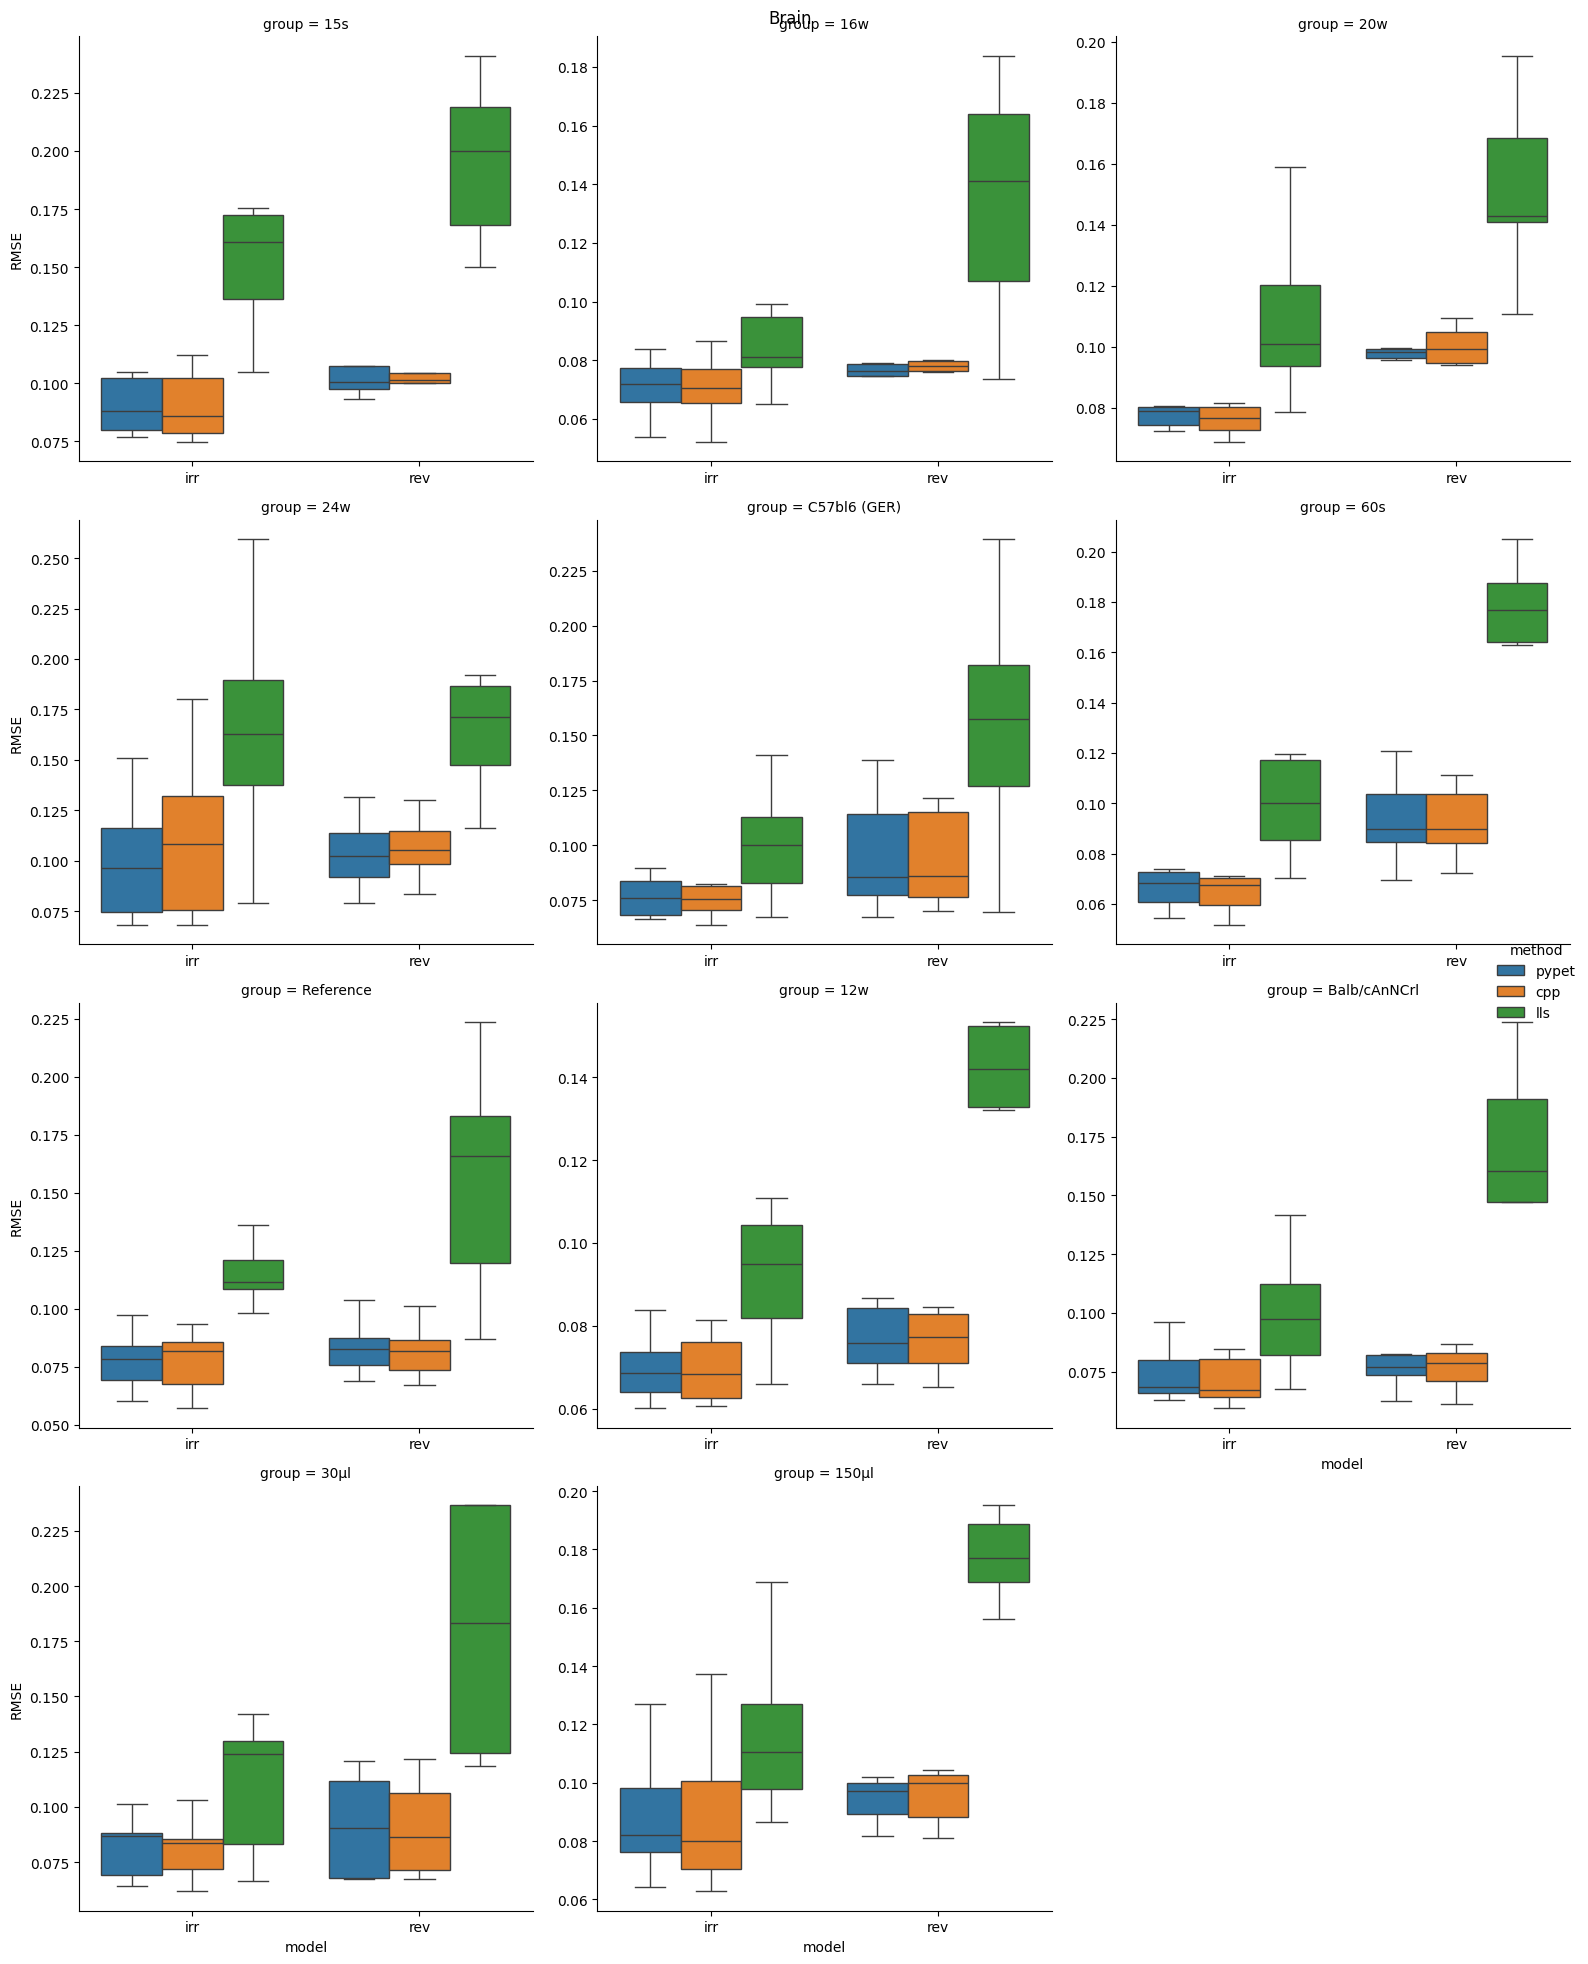

In [57]:
g = sns.catplot(
    fits.query("region == 'Brain'"),
    x="model",
    y="RMSE",
    hue="method",
    kind="box",
    col="group",
    col_wrap=3,
    sharey=False,
    sharex=False,
    showfliers=False,
    hue_order=["pypet", "cpp", "lls"],
)
g.fig.suptitle("Brain")
plt.tight_layout()
plt.savefig("group-method-comparison-brain.pdf", dpi=600)
plt.show()

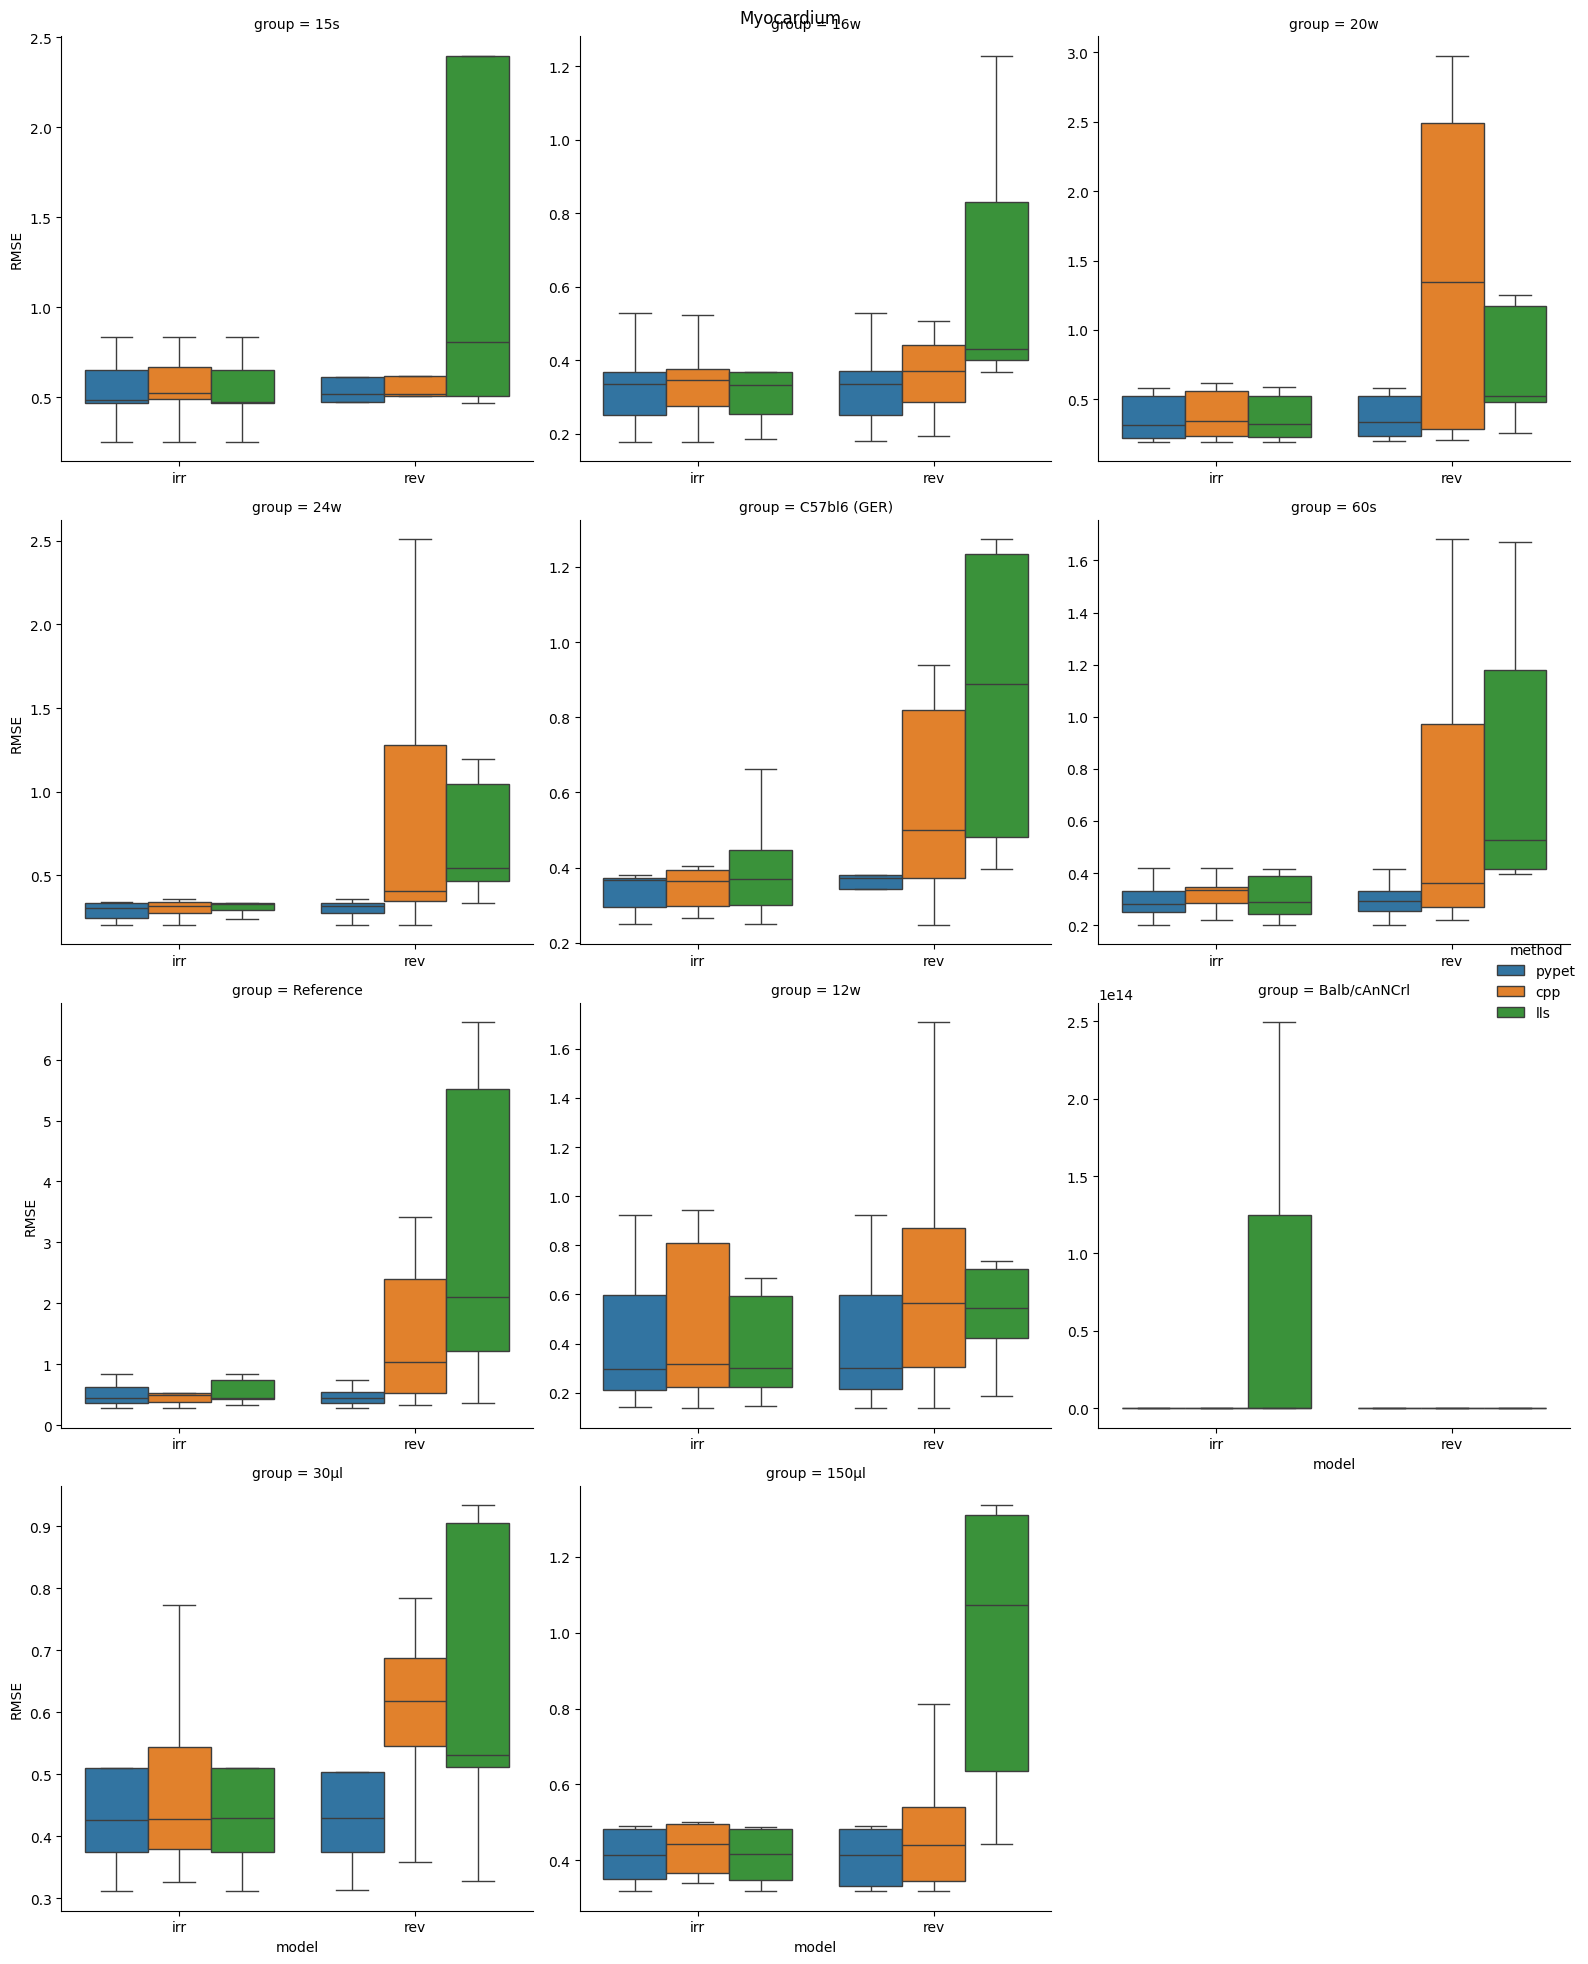

In [58]:
g = sns.catplot(
    fits.query("region == 'Myocardium'"),
    x="model",
    y="RMSE",
    hue="method",
    kind="box",
    col="group",
    col_wrap=3,
    sharey=False,
    sharex=False,
    showfliers=False,
    hue_order=["pypet", "cpp", "lls"],
)
g.fig.suptitle("Myocardium")
plt.tight_layout()
plt.savefig("group-method-comparison-myocardium.pdf", dpi=600)
plt.show()

# Curve comparisons

In [59]:
fits.head(2).to_clipboard()

In [60]:
def parse_array_string(s):
    if isinstance(s, np.ndarray):
        return s
    if pd.isna(s):
        return np.nan
    if isinstance(s, str):
        s = s.strip().strip("[]")
        return np.fromstring(s, sep=" ")
    raise TypeError(f"Unexpected type: {type(s)}")

In [61]:
df = fits.copy()

In [62]:
df["fit_arr"] = df["fit"].apply(parse_array_string)
df["real_arr"] = df["real_curve"].apply(parse_array_string)

In [63]:
id_cols = ["sample_id", "method", "region", "model"]

rows = []
for _, row in df.iterrows():
    fit = row["fit_arr"]
    real = row["real_arr"]
    
    n = len(real)
    
    for t in range(n):
        rows.append({
            "sample_id": row["sample_id"],
            "method": row["method"],
            "region": row["region"],
            "model": row["model"],
            "time_idx": t,
            #"curve_type": "real",
            "error": real[t] - fit[t],
        })
        #rows.append({
        #    "sample_id": row["sample_id"],
        #    "method": row["method"],
        #    "region": row["region"],
        #    "model": row["model"],
        #    "time_idx": t,
        #    "curve_type": "fit",
        #    "value": fit[t],
        #})

long_df = pd.DataFrame(rows)

In [64]:
long_df.head()

,sample_id,method,region,model,time_idx,error
0,AA1,cpp,Brain,irr,0,-0.001889
1,AA1,cpp,Brain,irr,1,-0.001303
2,AA1,cpp,Brain,irr,2,-0.049681
3,AA1,cpp,Brain,irr,3,-0.064140
4,AA1,cpp,Brain,irr,4,-0.089878


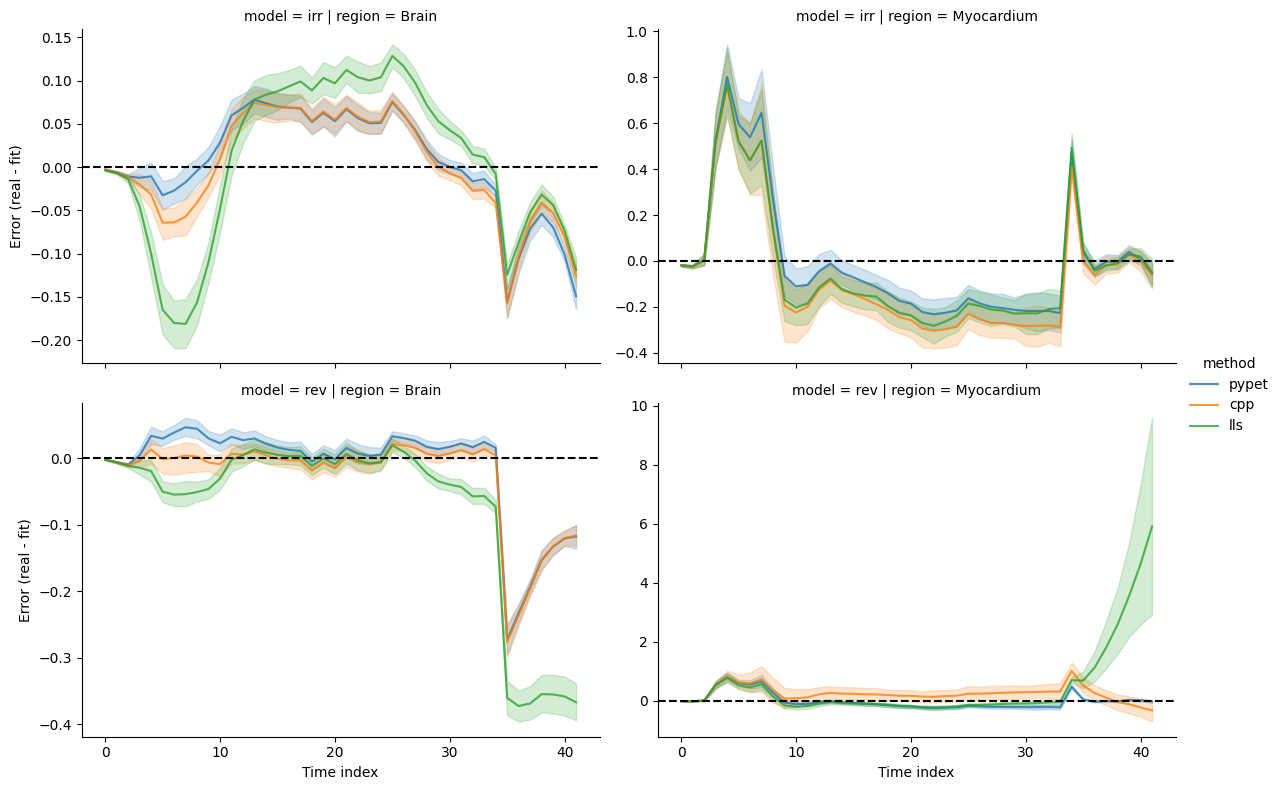

In [65]:
g = sns.relplot(
    data=long_df.query("error < 100"),
    x="time_idx",
    y="error",
    kind="line",
    hue="method",      # fit vs real
    #units="sample_id",     # separate line per sample
    #estimator=None,        # do not average across samples
    col="region",
    row="model",
    height=4,
    aspect=1.5,
    alpha=0.8,
    facet_kws={"sharey": False},
    hue_order=["pypet", "cpp", "lls"],
)
for ax in g.axes.flat:
    ax.axhline(y=0, linestyle="--", color="black")

g.set_axis_labels("Time index", "Error (real - fit)")
plt.savefig("curve-comparisons.pdf", dpi=600)
plt.show()